In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [6]:
df = pd.read_csv('/Users/rubyestrickland/Desktop/EnvDataSci/HW08/Waves_2023.txt', sep=r'\s+')

In [8]:
df= df.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
df.describe()

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000
mean,2023.0,6.526063,15.800579,11.499277,40.985594,1.083535,12.161879,6.813054,234.556205,17.196535
std,0.0,3.467253,8.817920,6.925343,15.007646,2.296129,4.165737,2.803208,49.429981,2.564664
min,2023.0,1.000000,1.000000,0.000000,0.000000,0.330000,2.860000,3.420000,10.000000,11.800000
25%,2023.0,4.000000,8.000000,5.000000,26.000000,0.730000,9.090000,5.500000,179.000000,14.600000
50%,2023.0,6.000000,16.000000,11.000000,26.000000,0.880000,12.500000,6.360000,263.000000,17.500000
75%,2023.0,10.000000,23.000000,18.000000,56.000000,1.140000,14.290000,7.550000,271.000000,19.400000
max,2023.0,12.000000,31.000000,23.000000,56.000000,99.000000,99.000000,99.000000,999.000000,23.900000


In [9]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

df = df[df['WVHT'] < 99]
df = df[df['DPD'] < 99]
df = df[df['APD'] < 99]
df = df[df['MWD'] < 999]

In [12]:
# Select every column EXCEPT the first (Time). Hint: iloc[rows, columns]; use a slice for columns.
df = df.iloc[:, 1:]
df.head()

,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
0,1,1,0,26,1.12,12.50,7.69,269,15.3
1,1,1,0,56,1.16,11.76,7.34,272,15.3
2,1,1,1,26,1.20,12.50,7.08,268,15.3
3,1,1,1,56,1.25,10.53,7.33,268,15.4
4,1,1,2,26,1.27,10.53,7.57,268,15.5


In [13]:
def z_score(df):
    # subtract the column mean, then divide by the column standard deviation
    return (df - df.mean()) / df.std()

In [14]:
# now standardize the data
df_z = z_score(df) # 
df_z.head()

,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
0,-1.593249,-1.678606,-1.660459,-0.999740,0.166100,0.104602,0.499276,0.753178,-0.738984
1,-1.593249,-1.678606,-1.660459,1.000203,0.242054,-0.097312,0.310355,0.818029,-0.738984
2,-1.593249,-1.678606,-1.516065,-0.999740,0.318007,0.104602,0.170014,0.731562,-0.738984
3,-1.593249,-1.678606,-1.516065,1.000203,0.412949,-0.432925,0.304957,0.731562,-0.699994
4,-1.593249,-1.678606,-1.371670,-0.999740,0.450926,-0.432925,0.434503,0.731562,-0.661003


In [15]:
from sklearn.decomposition import PCA

In [27]:
pca = PCA(n_components=9)
df_scaled = pca.fit_transform(df_z)

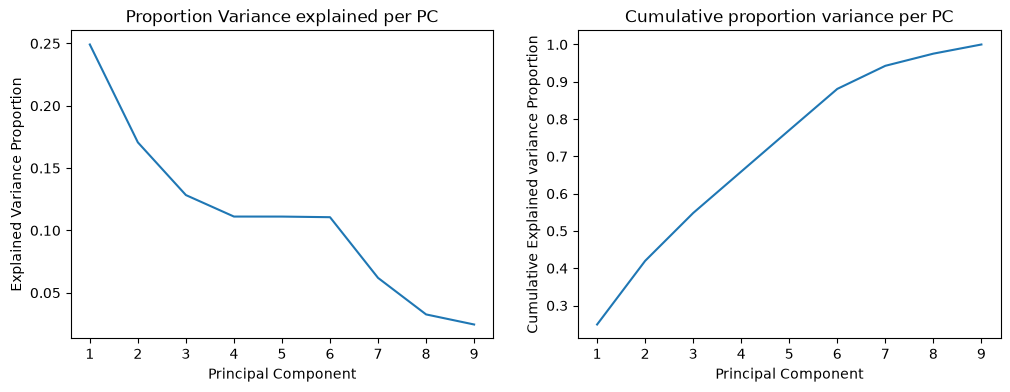

In [18]:
# The fraction of variance explained by each PC is stored in the fitted PCA object
variance_props = pca.explained_variance_ratio_ # check first 10
f, ax = plt.subplots(1,2, figsize=(12,4))

xdata = range(1,len(variance_props)+1)

ax[0].plot(xdata, variance_props)
ax[0].set_xticks(xdata)
ax[0].set_ylabel('Explained Variance Proportion')
ax[0].set_xlabel('Principal Component')
ax[0].set_title('Proportion Variance explained per PC')

# Cumulative variance: running total of variance_props (hint: np.cumsum)
ax[1].plot(xdata, np.cumsum(variance_props))
ax[1].set_xticks(xdata)
ax[1].set_ylabel('Cumulative Explained variance Proportion')
ax[1].set_xlabel('Principal Component')
ax[1].set_title('Cumulative proportion variance per PC')

plt.show()

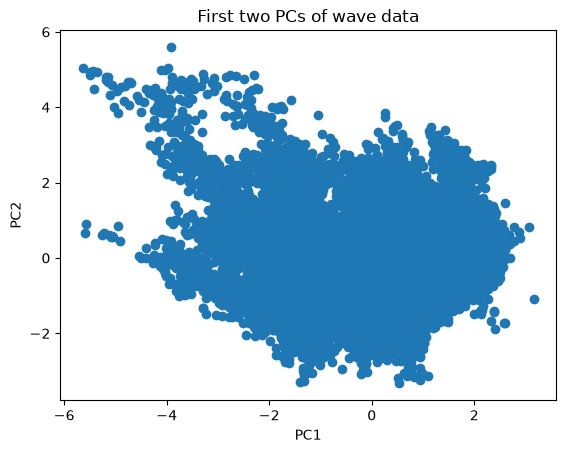

In [19]:
# PC2 vs PC1 (Remember that Python indexes from 0: column 0 is PC1)
plt.subplots()
plt.scatter(df_scaled[:, 0], df_scaled[:, 1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('First two PCs of wave data')
plt.show()

In [20]:
# View explained variance for each PC
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i+1}: {var:.2%} of variance")

PC1: 24.91% of variance
PC2: 17.06% of variance
PC3: 12.84% of variance
PC4: 11.11% of variance
PC5: 11.11% of variance
PC6: 11.06% of variance
PC7: 6.19% of variance
PC8: 3.26% of variance
PC9: 2.45% of variance


In [21]:
# Create a readable table of variables
pc_names = [f"PC{i+1}" for i in range(pca.n_components_)]
variables = pd.DataFrame(pca.components_.T, columns=pc_names, index=df_z.columns)

print(variables)

           PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
MM    0.463600  0.017351  0.584782  0.045361 -0.119397  0.006170 -0.143493   
DD    0.033113 -0.066000  0.051673 -0.101467  0.486279  0.862660  0.010245   
hh    0.008012  0.065017  0.145129 -0.366712  0.773471 -0.484176  0.056962   
mm   -0.000211  0.002405  0.005910  0.922502  0.372307 -0.101610  0.003052   
WVHT -0.448271  0.204727  0.349114  0.040391 -0.095636  0.061947  0.748358   
DPD   0.145926  0.695173 -0.255748  0.006232  0.008205  0.072033 -0.167799   
APD  -0.228479  0.629671  0.324892  0.006939 -0.014847  0.043836 -0.274774   
MWD  -0.442058 -0.262700  0.463860  0.012138 -0.027367  0.007291 -0.497085   
WTMP  0.560406  0.020856  0.355322  0.017150 -0.047155  0.005225  0.255461   

           PC8       PC9  
MM   -0.266067 -0.578853  
DD    0.006755 -0.027960  
hh   -0.060143 -0.024933  
mm    0.001467 -0.001145  
WVHT -0.240733 -0.051500  
DPD  -0.598587  0.195639  
APD   0.605236 -0.041899  
MWD

In [23]:
# Automatically list top contributing variables for PC1 and PC2 (sorted by absolute weight)
print("Top contributors to PC1:\n", variables['PC1'].abs().sort_values(ascending=False))
print("\nTop contributors to PC2:\n", variables['PC2'].abs().sort_values(ascending=False))

Top contributors to PC1:
 WTMP    0.560406
MM      0.463600
WVHT    0.448271
MWD     0.442058
APD     0.228479
DPD     0.145926
DD      0.033113
hh      0.008012
mm      0.000211
Name: PC1, dtype: float64

Top contributors to PC2:
 DPD     0.695173
APD     0.629671
MWD     0.262700
WVHT    0.204727
DD      0.066000
hh      0.065017
WTMP    0.020856
MM      0.017351
mm      0.002405
Name: PC2, dtype: float64


        PC1       PC2       PC3       PC4       PC5       PC6  Cluster
0 -1.727655  0.180610 -0.985091 -0.208005 -2.290772 -0.511019        2
1 -1.777092 -0.075390 -0.926414  1.638230 -1.554070 -0.731880        2
2 -1.709808  0.019449 -1.028104 -0.257368 -2.188135 -0.586112        2
3 -1.840210 -0.244195 -0.787972  1.589672 -1.460874 -0.816044        2
4 -1.863404 -0.149457 -0.709634 -0.305127 -2.101177 -0.674509        2


/var/folders/32/bnhb91_d3lb3xp_n4tdhd64c0000gn/T/ipykernel_77456/3630174913.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


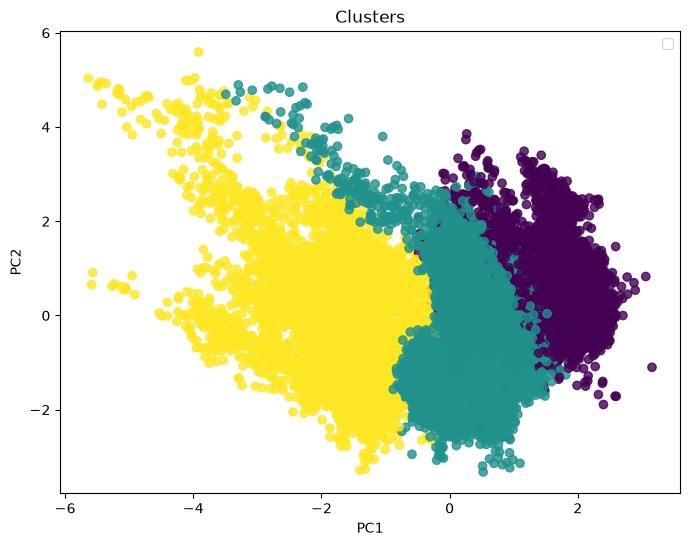

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Run PCA on your scaled data (keeping 6 components)
pca = PCA(n_components=6)
pca_data = pca.fit_transform(df_scaled)

# 2. Build pca_df with named columns
pc_cols = [f'PC{i+1}' for i in range(6)]
pca_df = pd.DataFrame(pca_data, columns=pc_cols)

# 3. Fit K-Means on the reduced PC space
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
clusters = kmeans.fit_predict(pca_df[pc_cols])

# 4. Add cluster labels to pca_df
pca_df['Cluster'] = clusters
print(pca_df.head())

# 5. Visualize the clusters in 2D PC space
plt.figure(figsize=(8, 6))
plt.scatter(
    pca_df['PC1'], 
    pca_df['PC2'], 
    c=pca_df['Cluster'], 
    cmap='viridis', 
    alpha=0.8
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters')
plt.legend()
plt.show()


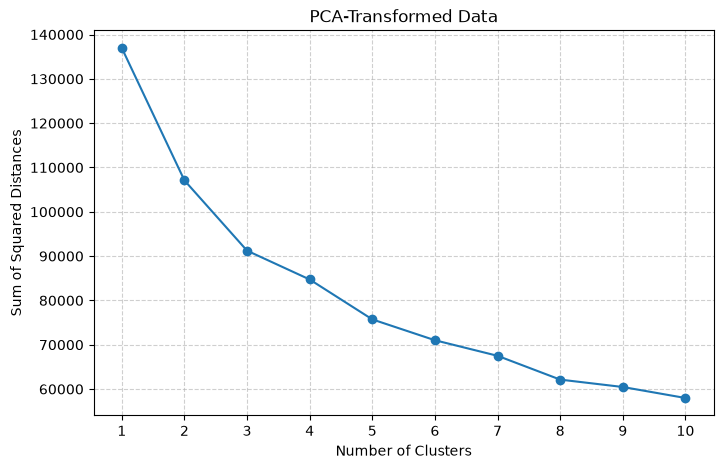

In [41]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Transform scaled data using the top 6 PCs (change to 7 if preferred)
pca = PCA(n_components=6)
pca_data = pca.fit_transform(df_scaled)

# 2. Run K-Means for 1 to 10 clusters and record Sum of Squared Distances (inertia)
ssd = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(pca_data)
    ssd.append(kmeans.inertia_)

# 3. Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, ssd, marker='o', linestyle='-')
plt.xticks(k_range)
plt.xlabel('Number of Clusters')
plt.ylabel('Sum of Squared Distances')
plt.title('PCA-Transformed Data')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

        PC1       PC2       PC3       PC4       PC5       PC6  Cluster
0 -1.727655  0.180610 -0.985091 -0.208005 -2.290772 -0.511019        2
1 -1.777092 -0.075390 -0.926414  1.638230 -1.554070 -0.731880        2
2 -1.709808  0.019449 -1.028104 -0.257368 -2.188135 -0.586112        2
3 -1.840210 -0.244195 -0.787972  1.589672 -1.460874 -0.816044        2
4 -1.863404 -0.149457 -0.709634 -0.305127 -2.101177 -0.674509        2


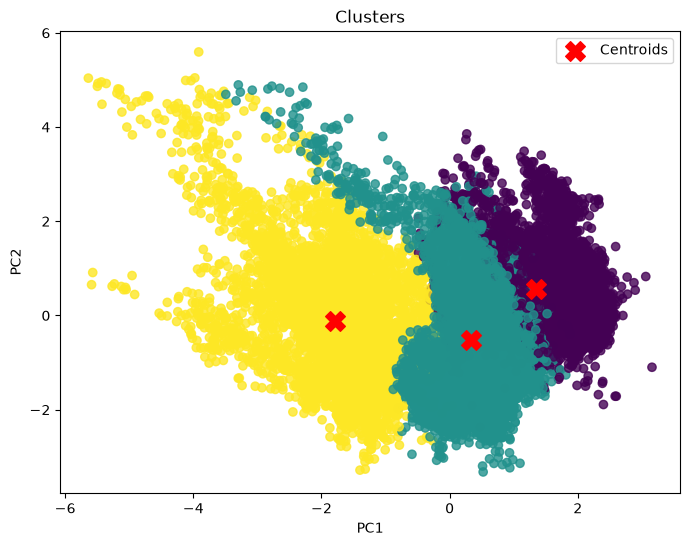

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Run PCA on your scaled data (keeping 6 components)
pca = PCA(n_components=6)
pca_data = pca.fit_transform(df_scaled)

# 2. Build pca_df with named columns
pc_cols = [f'PC{i+1}' for i in range(6)]
pca_df = pd.DataFrame(pca_data, columns=pc_cols)

# 3. Fit K-Means on the reduced PC space
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
clusters = kmeans.fit_predict(pca_df[pc_cols])

# 4. Add cluster labels to pca_df
pca_df['Cluster'] = clusters
print(pca_df.head())

# 5. Visualize the clusters in 2D PC space
plt.figure(figsize=(8, 6))
plt.scatter(
    pca_df['PC1'], 
    pca_df['PC2'], 
    c=pca_df['Cluster'], 
    cmap='viridis', 
    alpha=0.8
)

# Plot cluster centroids
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    c='red', 
    marker='X', 
    s=200, 
    label='Centroids'
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters')
plt.legend()
plt.show()
